# Eksploracyjna analiza danych: ceny domów

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 90)

df = pd.read_csv("train.csv")
df.shape

(1460, 81)

In [2]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Pytania naprowadzające i przegląd zbioru

Zmienna docelowa to `SalePrice`, czyli cena sprzedaży domu w USD. Chcemy ją przewidywać na podstawie cech domu, więc jest to zadanie regresji.

Zbiór ma 81 kolumn: `Id`, 79 cech i `SalePrice`. Cechy są trzech rodzajów:
- liczbowe: powierzchnie (`GrLivArea`, `LotArea`, `TotalBsmtSF`), liczby pomieszczeń, lata (`YearBuilt`, `YrSold`);
- porządkowe: oceny jakości i stanu, np. `OverallQual` w skali 1-10 albo `ExterQual` (Po < Fa < TA < Gd < Ex);
- nominalne: dzielnica (`Neighborhood`), typ budynku (`BldgType`), strefa zabudowy (`MSZoning`) i inne.

`MSSubClass` jest zapisany liczbami, ale to kod typu zabudowy, więc traktujemy go jak kategorię. Kolumn z wolnym tekstem nie ma, wszystkie kolumny tekstowe są kategoriami.

In [3]:
print("Typy danych (liczba kolumn):")
print(df.dtypes.value_counts(), "\n")
df.dtypes.to_frame("dtype").T

Typy danych (liczba kolumn):
str        43
int64      35
float64     3
Name: count, dtype: int64 



,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
dtype,int64,int64,str,float64,int64,str,str,str,str,str,str,str,str,str,str,str,str,int64,int64,int64,int64,str,str,str,str,str,float64,str,str,str,str,str,str,str,int64,str,int64,int64,int64,str,str,str,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,int64,str,int64,str,str,float64,str,int64,int64,str,str,str,int64,int64,int64,int64,int64,int64,str,str,str,int64,int64,int64,str,str,int64


In [4]:
num_cols = df.select_dtypes("number").columns.drop("Id")
cat_cols = df.select_dtypes(exclude="number").columns
print(f"Kolumny liczbowe: {len(num_cols)}, kategoryczne (tekstowe): {len(cat_cols)}")

Kolumny liczbowe: 37, kategoryczne (tekstowe): 43


### Statystyki opisowe: zmienne liczbowe

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


### Statystyki opisowe: zmienne kategoryczne

In [6]:
df.describe(exclude='number').T.sort_values('unique', ascending=False)

,count,unique,top,freq
Neighborhood,1460,25,NAmes,225
Exterior2nd,1460,16,VinylSd,504
Exterior1st,1460,15,VinylSd,515
SaleType,1460,9,WD,1267
Condition1,1460,9,Norm,1260
Condition2,1460,8,Norm,1445
HouseStyle,1460,8,1Story,726
RoofMatl,1460,8,CompShg,1434
Functional,1460,7,Typ,1360
BsmtFinType2,1422,6,Unf,1256


### Braki danych i ich znaczenie

`pd.read_csv()` domyślnie zamienia na `NaN` napisy `"NA"` oraz `"None"`. Tymczasem według `data_description.txt` w wielu kolumnach `NA` oznacza, że dom nie ma danej rzeczy: `PoolQC = NA` to dom bez basenu, `GarageType = NA` to dom bez garażu. W `MasVnrType` słowo `None` znaczy „brak okładziny”.

In [7]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
braki = pd.DataFrame({"liczba_NaN": na, "procent": (na / len(df) * 100).round(1)})
braki

,liczba_NaN,procent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


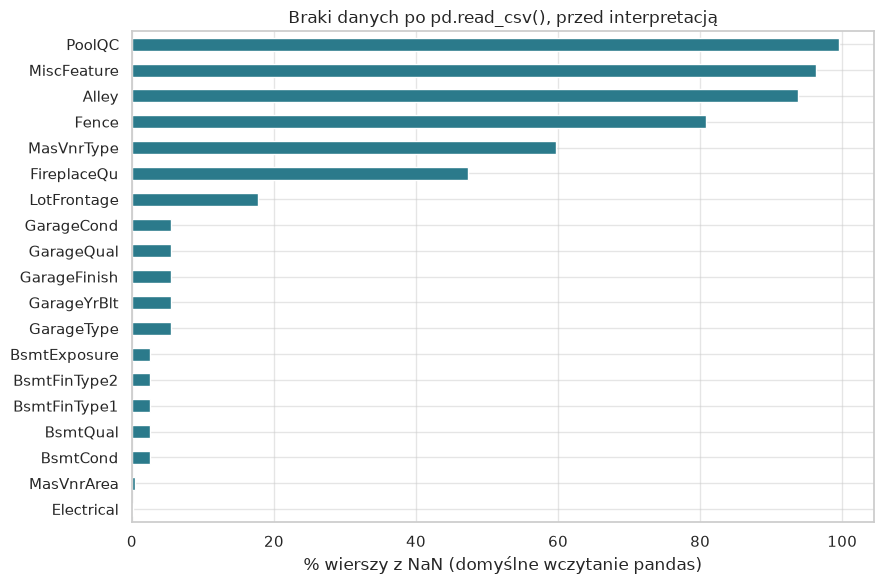

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
braki["procent"].sort_values().plot.barh(ax=ax, color="#2b7a8b")
ax.set_xlabel("% wierszy z NaN (domyślne wczytanie pandas)")
ax.set_title("Braki danych po pd.read_csv(), przed interpretacją")
plt.tight_layout()

Dla porównania wczytujemy plik tak, żeby pandas nie zamieniał tych napisów na `NaN` (`keep_default_na=False`):

In [9]:
raw = pd.read_csv("train.csv", keep_default_na=False, na_values=[""])
porown = pd.DataFrame({
    "NaN_domyslnie": df.isna().sum(),
    "napis_NA": (raw == "NA").sum(),
    "napis_None": (raw == "None").sum(),
}).loc[na.index]
porown

,NaN_domyslnie,napis_NA,napis_None
PoolQC,1453,1453,0
MiscFeature,1406,1406,0
Alley,1369,1369,0
Fence,1179,1179,0
MasVnrType,872,8,864
FireplaceQu,690,690,0
LotFrontage,259,259,0
GarageType,81,81,0
GarageYrBlt,81,81,0
GarageFinish,81,81,0


Co oznaczają braki według `data_description.txt`:

| Kolumny | Co znaczy NA | Rodzaj braku |
|---|---|---|
| `PoolQC` | brak basenu | strukturalny (cecha nie istnieje) |
| `MiscFeature` | brak dodatkowej cechy | strukturalny |
| `Alley` | brak dojazdu alejką | strukturalny |
| `Fence` | brak ogrodzenia | strukturalny |
| `FireplaceQu` | brak kominka (zgadza się z `Fireplaces == 0`) | strukturalny |
| `Garage*` (5 kolumn, po 81) | brak garażu (zgadza się z `GarageArea == 0`) | strukturalny; w `GarageYrBlt` nie da się wpisać sensownego roku |
| `Bsmt*` (37-38) | brak piwnicy (`TotalBsmtSF == 0`) | strukturalny, ale w `BsmtExposure` i `BsmtFinType2` jest po jednym domu z piwnicą i bez wartości, czyli prawdziwy brak |
| `MasVnrType` (872 po wczytaniu) | 864 to napis `"None"` (brak okładziny), który pandas zamienił na NaN; prawdziwych NA jest 8 | głównie skutek wczytywania |
| `MasVnrArea` (8) | prawdziwy brak | losowy |
| `LotFrontage` (259, 18%) | prawdziwy brak (opis nie przewiduje NA) | do uzupełnienia, np. medianą w dzielnicy |
| `Electrical` (1) | prawdziwy brak | jeden wiersz |

Usuwanie wierszy z NaN albo wstawianie średniej byłoby więc błędem, bo większość tych wartości mówi, że domu czegoś brakuje. Prawdziwych braków jest niewiele: `LotFrontage`, po 8 w `MasVnr*`, 1 w `Electrical` i 2 w `Bsmt*`.

In [10]:
# Weryfikacja: czy NA w kolumnach garażu/piwnicy/kominka pokrywa się z brakiem tej części domu?
print("Garaż:   NA w GarageType i GarageArea==0 ->", ((df.GarageType.isna()) == (df.GarageArea == 0)).all())
print("Kominek: NA w FireplaceQu i Fireplaces==0 ->", ((df.FireplaceQu.isna()) == (df.Fireplaces == 0)).all())
print("Basen:   NA w PoolQC i PoolArea==0        ->", ((df.PoolQC.isna()) == (df.PoolArea == 0)).all())
print("Piwnica: NA w BsmtQual i TotalBsmtSF==0   ->", ((df.BsmtQual.isna()) == (df.TotalBsmtSF == 0)).all())
print("\nDomy z piwnicą, ale bez BsmtExposure / BsmtFinType2:")
df.loc[(df.TotalBsmtSF > 0) & (df.BsmtExposure.isna() | df.BsmtFinType2.isna()),
       ["Id", "TotalBsmtSF", "BsmtQual", "BsmtExposure", "BsmtFinType2"]]

Garaż:   NA w GarageType i GarageArea==0 -> True
Kominek: NA w FireplaceQu i Fireplaces==0 -> True
Basen:   NA w PoolQC i PoolArea==0        -> True
Piwnica: NA w BsmtQual i TotalBsmtSF==0   -> True

Domy z piwnicą, ale bez BsmtExposure / BsmtFinType2:


,Id,TotalBsmtSF,BsmtQual,BsmtExposure,BsmtFinType2
332,333,3206,Gd,No,NaN
948,949,936,Gd,NaN,Unf


Poprawione wczytanie: braki strukturalne zastępujemy kategorią `"Brak"`, a rok budowy garażu dla domów bez garażu zostaje `NaN`. Prawdziwych braków na etapie EDA nie uzupełniamy.

In [11]:
strukturalne = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
dfc = df.copy()
for c in strukturalne:
    if c.startswith("Garage"):
        dfc.loc[df.GarageArea == 0, c] = "Brak"      # tylko domy bez garażu
    elif c.startswith("Bsmt"):
        dfc.loc[df.TotalBsmtSF == 0, c] = "Brak"     # tylko domy bez piwnicy
    else:
        dfc[c] = dfc[c].fillna("Brak")
dfc["MasVnrType"] = raw["MasVnrType"].replace("NA", np.nan)   # przywracamy "None" jako kategorię
pozostale = dfc.isna().sum()
pozostale[pozostale > 0]

LotFrontage     259
MasVnrType        8
MasVnrArea        8
BsmtExposure      1
BsmtFinType2      1
Electrical        1
GarageYrBlt      81
dtype: int64

### Zakres danych
Oprócz domów jednorodzinnych zbiór zawiera szeregowce, bliźniaki i domy dwurodzinne. Mieszkań w blokach nie ma, więc model zbudowany na tych danych nie wyceni typowego polskiego mieszkania.

In [12]:
print(df.BldgType.value_counts())
print("\nLata sprzedaży:", df.YrSold.min(), "-", df.YrSold.max())

BldgType
1Fam      1220
TwnhsE     114
Duplex      52
Twnhs       43
2fmCon      31
Name: count, dtype: int64

Lata sprzedaży: 2006 - 2010


## 2. Wykresy podobne do tych z wykładu

### Wykres pudełkowy: cena a ogólna jakość (`OverallQual`)

OverallQual,1,2,3,4,5,6,7,8,9,10
count,2.0,3.0,20.0,116.0,397.0,374.0,319.0,168.0,43.0,18.0
median,50150.0,60000.0,86250.0,108000.0,133000.0,160000.0,200141.0,269750.0,345000.0,432390.0


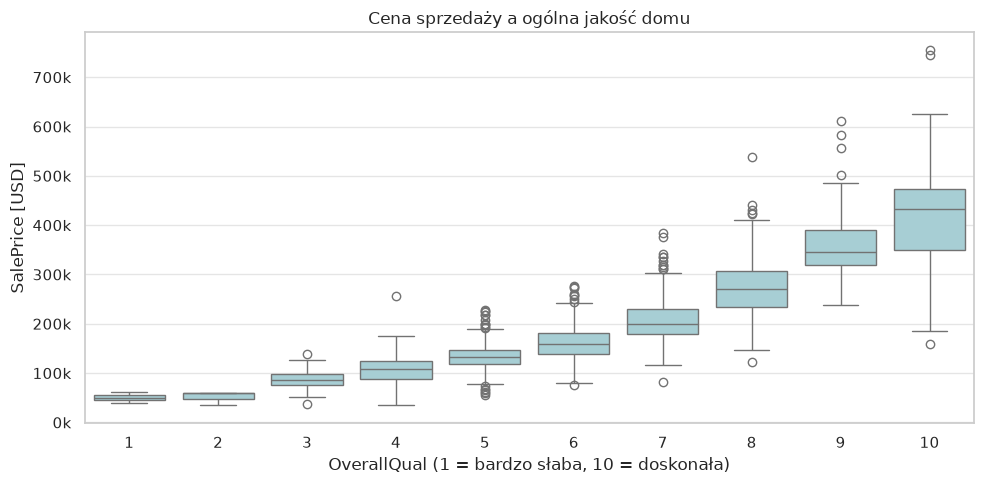

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", color="#9fd3dc", ax=ax)
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.set_title("Cena sprzedaży a ogólna jakość domu")
ax.set_xlabel("OverallQual (1 = bardzo słaba, 10 = doskonała)"); ax.set_ylabel("SalePrice [USD]")
plt.tight_layout()
df.groupby("OverallQual").SalePrice.agg(["count", "median"]).T

Cena rośnie z każdym stopniem jakości: mediana wynosi ok. 50 tys. USD przy ocenie 1 i ok. 432 tys. przy ocenie 10. Ze wszystkich zmiennych `OverallQual` jest najsilniej skorelowana z ceną (r ≈ 0,79). W grupie 10 są dwa domy sprzedane poniżej 200 tys.; wracamy do nich w części 4.

### Wykres słupkowy: instalacja elektryczna (`Electrical`)

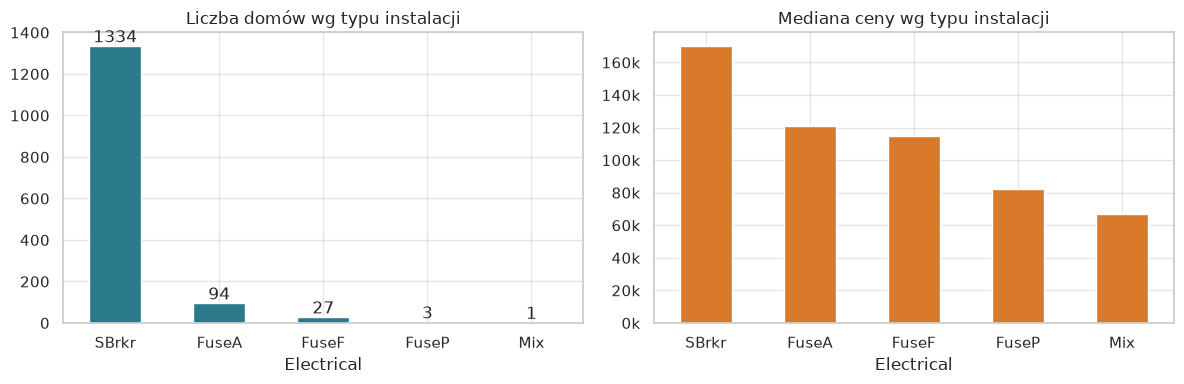

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cnt = df.Electrical.value_counts()
cnt.plot.bar(ax=axes[0], color="#2b7a8b"); axes[0].set_title("Liczba domów wg typu instalacji")
for i, v in enumerate(cnt): axes[0].text(i, v, str(v), ha="center", va="bottom")
med = df.groupby("Electrical").SalePrice.median().reindex(cnt.index)
med.plot.bar(ax=axes[1], color="#d97a2b"); axes[1].set_title("Mediana ceny wg typu instalacji")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
for a in axes: a.tick_params(axis="x", rotation=0)
plt.tight_layout()

91% domów ma nowoczesne wyłączniki (`SBrkr`), więc ta cecha słabo różnicuje domy. Domy ze starymi bezpiecznikami (`FuseA`, `FuseF`, `FuseP`) są jednak wyraźnie tańsze, prawdopodobnie dlatego, że są starsze. Mediany dla `FuseP` (3 domy) i `Mix` (1 dom) niewiele znaczą.

### Wykres liniowy: liczba sprzedaży w kolejnych miesiącach

MoSold,1,2,3,4,5,6,7,8,9,10,11,12
transakcje,58,52,106,141,204,253,234,122,63,89,79,59


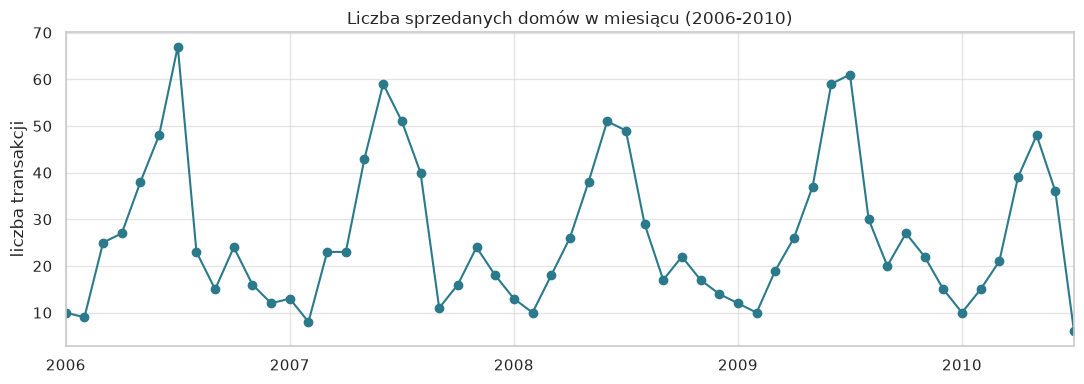

In [15]:
sprz = (df.assign(data=pd.to_datetime(dict(year=df.YrSold, month=df.MoSold, day=1)))
          .groupby("data").size())
fig, ax = plt.subplots(figsize=(11, 4))
sprz.plot(ax=ax, marker="o", color="#2b7a8b")
ax.set_title("Liczba sprzedanych domów w miesiącu (2006-2010)"); ax.set_ylabel("liczba transakcji"); ax.set_xlabel("")
plt.tight_layout()
df.MoSold.value_counts().sort_index().to_frame("transakcje").T

Sprzedaż jest sezonowa: najwięcej transakcji przypada na maj, czerwiec i lipiec, najmniej na zimę. Spadek na końcu wykresu wynika z tego, że dane kończą się w lipcu 2010, i nie jest trendem rynkowym.

### Mapa ciepła korelacji dla 10 zmiennych najsilniej związanych z ceną

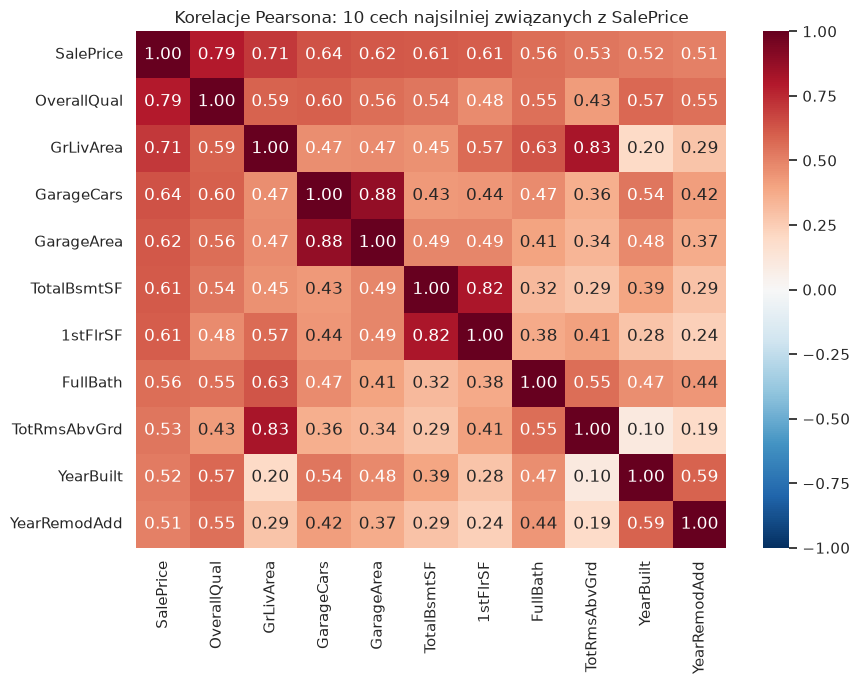

In [16]:
top = df[num_cols].corr()["SalePrice"].abs().sort_values(ascending=False).head(11).index
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelacje Pearsona: 10 cech najsilniej związanych z SalePrice")
plt.tight_layout()

Z ceną najsilniej wiążą się jakość (`OverallQual`), powierzchnia mieszkalna (`GrLivArea`), garaż (`GarageCars`, `GarageArea`) i piwnica (`TotalBsmtSF`, `1stFlrSF`). Niektóre cechy prawie się dublują: `GarageCars` i `GarageArea` (0,88), `TotalBsmtSF` i `1stFlrSF` (0,82), `GrLivArea` i `TotRmsAbvGrd` (0,83). W modelu wystarczy po jednej cesze z każdej pary.

### Cena wg dzielnicy (`Neighborhood`)

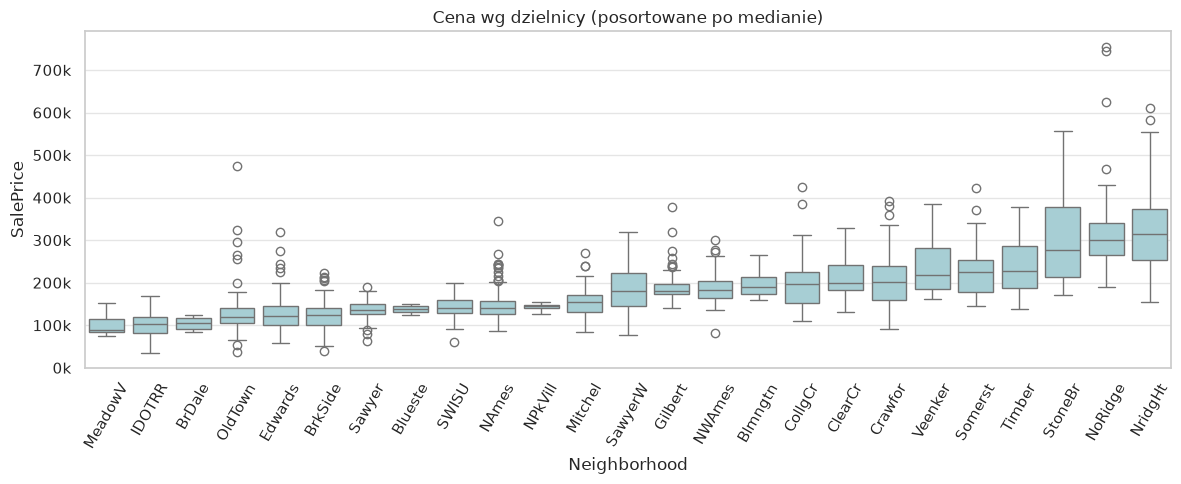

In [17]:
kol = df.groupby("Neighborhood").SalePrice.median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=kol, color="#9fd3dc", ax=ax)
ax.tick_params(axis="x", rotation=60); ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.set_title("Cena wg dzielnicy (posortowane po medianie)")
plt.tight_layout()

Lokalizacja mocno wpływa na cenę. Mediana w `MeadowV` to 88 tys., w `IDOTRR` i `BrDale` ok. 105 tys., a w `StoneBr`, `NoRidge` i `NridgHt` od 280 do 315 tys., czyli ponad trzy razy więcej.

## 3. Analiza zmiennej docelowej `SalePrice`

Szukamy odpowiedzi na pytania: jaki jest rozkład cen, czy są wartości odstające, ile wynoszą średnia i mediana i czy rozkład jest normalny.

### Histogram dla 10, 30 i 50 przedziałów

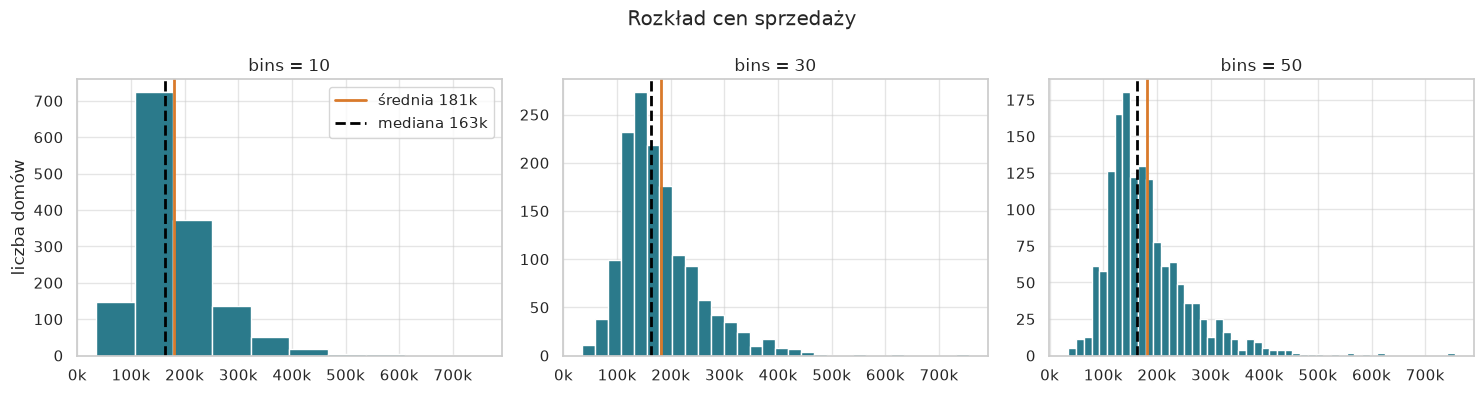

In [18]:
p = df["SalePrice"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, b in zip(axes, [10, 30, 50]):
    ax.hist(p, bins=b, color="#2b7a8b", edgecolor="white")
    ax.axvline(p.mean(), color="#d97a2b", lw=2, label=f"średnia {p.mean()/1000:.0f}k")
    ax.axvline(p.median(), color="black", ls="--", lw=2, label=f"mediana {p.median()/1000:.0f}k")
    ax.set_title(f"bins = {b}"); ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
axes[0].legend(); axes[0].set_ylabel("liczba domów")
fig.suptitle("Rozkład cen sprzedaży")
plt.tight_layout()

Przy 10 przedziałach każdy ma szerokość ok. 72 tys. USD. Widać tylko, że większość domów kosztuje od 100 do 250 tys. Przy 30 przedziałach rozkład ma jedno wyraźne maksimum przy 140-160 tys. i długi prawy ogon; ta wersja jest najczytelniejsza. Przy 50 przedziałach szczegółów jest więcej, ale w ogonie pojawiają się puste i pojedyncze słupki.

W każdej wersji rozkład jest prawostronnie skośny. Średnia jest większa od mediany, bo podnoszą ją drogie domy.

### Wykres pudełkowy cen

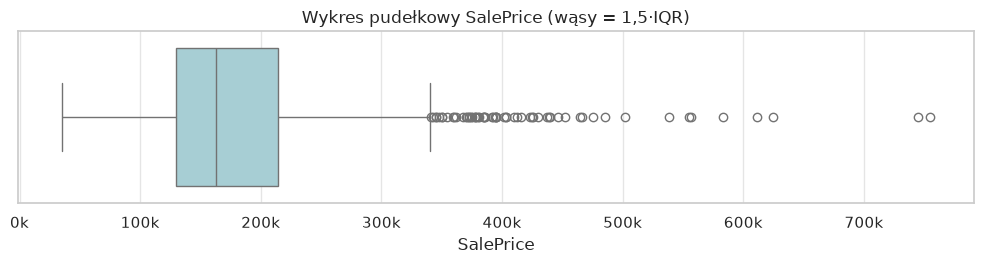

In [19]:
fig, ax = plt.subplots(figsize=(10, 2.8))
sns.boxplot(x=p, color="#9fd3dc", ax=ax)
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.set_title("Wykres pudełkowy SalePrice (wąsy = 1,5·IQR)")
plt.tight_layout()

### Statystyki: min, max, średnia, mediana, Q1, Q3, IQR

In [20]:
q1, q3 = p.quantile([0.25, 0.75])
iqr = q3 - q1
gora, dol = q3 + 1.5 * iqr, q1 - 1.5 * iqr
stat = pd.Series({
    "min": p.min(), "Q1": q1, "mediana": p.median(), "średnia": p.mean(),
    "Q3": q3, "max": p.max(), "IQR": iqr, "odch. std": p.std(),
    "skośność": p.skew(), "kurtoza (nadwyżka)": p.kurt(),
    "górna granica 1,5·IQR": gora,
    "liczba odstających (góra)": (p > gora).sum(),
    "liczba odstających (dół)": (p < dol).sum(),
})
stat.round(2).to_frame("SalePrice")

,SalePrice
min,34900.00
Q1,129975.00
mediana,163000.00
średnia,180921.20
Q3,214000.00
max,755000.00
IQR,84025.00
odch. std,79442.50
skośność,1.88
kurtoza (nadwyżka),6.54


Według reguły 1,5·IQR 61 domów (4%) kosztuje więcej niż ok. 340 tys. USD i jest wartościami odstającymi. Dolna granica wychodzi ujemna, więc odstających w dół nie ma. Sprawdźmy, jakie to domy:

In [21]:
drogie = df[p > gora]
pd.DataFrame({
    "drogie (>340k)": [drogie.OverallQual.median(), drogie.GrLivArea.median(), drogie.YearBuilt.median()],
    "wszystkie": [df.OverallQual.median(), df.GrLivArea.median(), df.YearBuilt.median()],
}, index=["mediana OverallQual", "mediana GrLivArea [ft²]", "mediana YearBuilt"])

,drogie (>340k),wszystkie
mediana OverallQual,9.0,6.0
mediana GrLivArea [ft²],2364.0,1464.0
mediana YearBuilt,2006.0,1973.0


In [22]:
drogie.Neighborhood.value_counts().head(5)

Neighborhood
NridgHt    27
NoRidge    11
StoneBr     9
Timber      3
Crawfor     3
Name: count, dtype: int64

Najdroższe domy są duże (mediana 2364 ft² wobec 1464 ft² w całym zbiorze), nowe (mediana roku budowy 2006) i wysokiej jakości (mediana oceny 9). 47 z 61 stoi w `NridgHt`, `NoRidge` i `StoneBr`. Nic nie wskazuje na błąd w danych, więc zostawiamy je w zbiorze.

### Czy ceny mają rozkład normalny?

Test Shapiro-Wilka   SalePrice:      p = 3.2e-33
Test Shapiro-Wilka   log(SalePrice): p = 1.1e-07


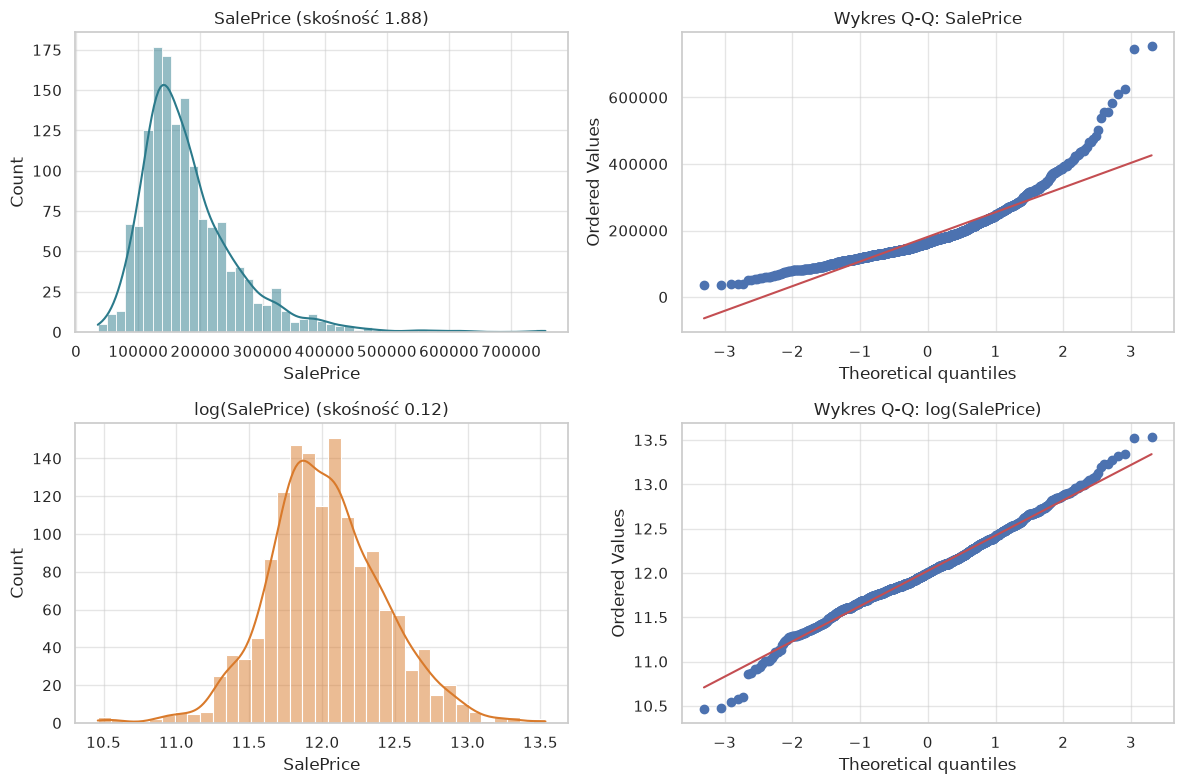

In [23]:
logp = np.log(p)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(p, kde=True, ax=axes[0, 0], color="#2b7a8b"); axes[0, 0].set_title(f"SalePrice (skośność {p.skew():.2f})")
stats.probplot(p, dist="norm", plot=axes[0, 1]); axes[0, 1].set_title("Wykres Q-Q: SalePrice")
sns.histplot(logp, kde=True, ax=axes[1, 0], color="#d97a2b"); axes[1, 0].set_title(f"log(SalePrice) (skośność {logp.skew():.2f})")
stats.probplot(logp, dist="norm", plot=axes[1, 1]); axes[1, 1].set_title("Wykres Q-Q: log(SalePrice)")
plt.tight_layout()
print("Test Shapiro-Wilka   SalePrice:      p =", f"{stats.shapiro(p).pvalue:.1e}")
print("Test Shapiro-Wilka   log(SalePrice): p =", f"{stats.shapiro(logp).pvalue:.1e}")

Nie. Histogram jest niesymetryczny (skośność ≈ 1,88, kurtoza ≈ 6,5, więc ogony są grube), a w prawym ogonie punkty na wykresie Q-Q odchodzą od prostej. Test Shapiro-Wilka zdecydowanie odrzuca normalność.

Po zlogarytmowaniu rozkład jest prawie symetryczny (skośność ≈ 0,12), a wykres Q-Q prawie prosty. Przy n = 1460 test nadal wykrywa drobne odchylenia, ale w praktyce to dobre przybliżenie rozkładu normalnego. Dlatego modele regresji często przewidują `log(SalePrice)`. Konkurs na Kaggle też liczy błąd (RMSE) na logarytmach cen.

## 4. Co wpływa na cenę domu? Hipoteza: „Większe domy są droższe”

### Zmienne związane z powierzchnią
Szukamy kolumn, które mają w nazwie „Area” albo „SF” (*square feet*, stopy kwadratowe; 1 ft² ≈ 0,093 m²).

In [24]:
area_cols = [c for c in df.columns if "Area" in c or "SF" in c]
korel = pd.DataFrame({
    "Pearson r": df[area_cols].corrwith(df.SalePrice),
    "Spearman ρ": df[area_cols].corrwith(df.SalePrice, method="spearman"),
    "% zer": (df[area_cols] == 0).mean().mul(100).round(1),
}).sort_values("Pearson r", ascending=False)
korel.round(3)

,Pearson r,Spearman ρ,% zer
GrLivArea,0.709,0.731,0.0
GarageArea,0.623,0.649,5.5
TotalBsmtSF,0.614,0.603,2.5
1stFlrSF,0.606,0.575,0.0
MasVnrArea,0.477,0.421,59.0
BsmtFinSF1,0.386,0.302,32.0
WoodDeckSF,0.324,0.354,52.1
2ndFlrSF,0.319,0.294,56.8
OpenPorchSF,0.316,0.478,44.9
LotArea,0.264,0.456,0.0


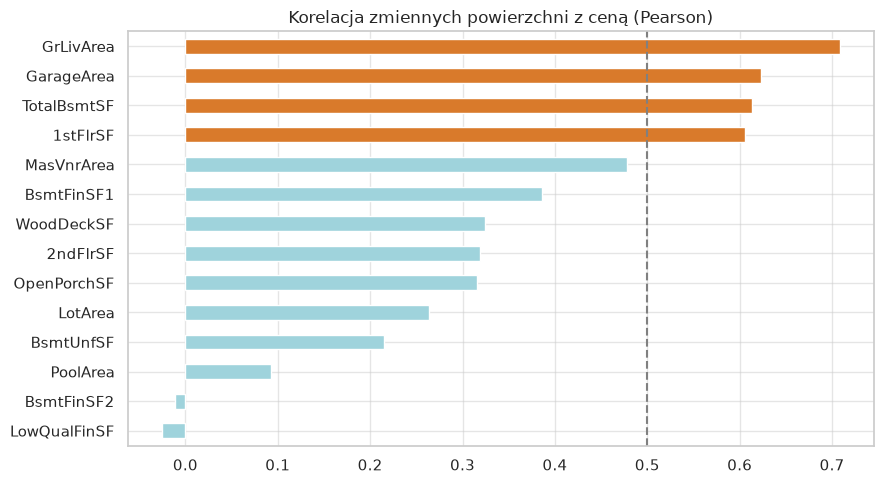

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
korel["Pearson r"].sort_values().plot.barh(ax=ax, color=np.where(korel["Pearson r"].sort_values() > 0.5, "#d97a2b", "#9fd3dc"))
ax.set_title("Korelacja zmiennych powierzchni z ceną (Pearson)"); ax.axvline(0.5, ls="--", c="grey")
plt.tight_layout()

Najsilniej z ceną wiąże się powierzchnia mieszkalna nad ziemią, `GrLivArea` (r ≈ 0,71). Dalej są powierzchnia garażu (0,62), piwnicy `TotalBsmtSF` (0,61) i parteru `1stFlrSF` (0,61). Powierzchnia działki `LotArea` ma r ≈ 0,26. Basen, `LowQualFinSF` i `BsmtFinSF2` prawie nie mają związku z ceną, bo u większości domów wynoszą 0.

### Wykres punktowy: powierzchnia mieszkalna (`GrLivArea`) a cena

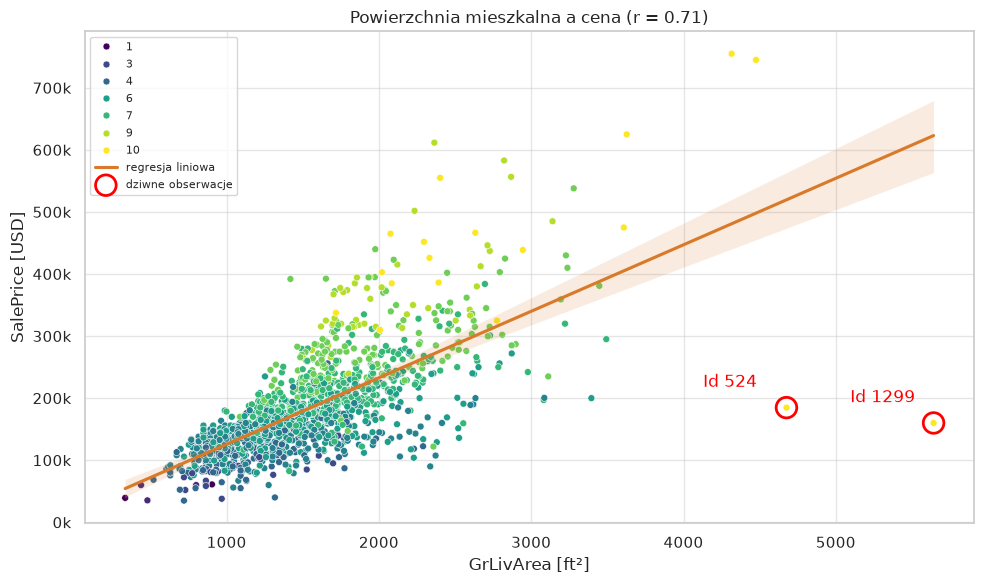

In [26]:
dziwne = df[(df.GrLivArea > 4000) & (df.SalePrice < 300000)]
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", s=25, ax=ax)
sns.regplot(data=df, x="GrLivArea", y="SalePrice", scatter=False, color="#d97a2b", ax=ax, label="regresja liniowa")
ax.scatter(dziwne.GrLivArea, dziwne.SalePrice, s=220, facecolors="none", edgecolors="red", lw=2, label="dziwne obserwacje")
for _, r in dziwne.iterrows():
    ax.annotate(f"Id {r.Id}", (r.GrLivArea, r.SalePrice), xytext=(-60, 15), textcoords="offset points", color="red")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.set_title(f"Powierzchnia mieszkalna a cena (r = {df.GrLivArea.corr(df.SalePrice):.2f})")
ax.set_xlabel("GrLivArea [ft²]"); ax.set_ylabel("SalePrice [USD]"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()

Czy zależność jest wyraźna? Tak: r ≈ 0,71 (Spearman ≈ 0,73). Większe domy są zdecydowanie droższe, więc hipoteza się potwierdza.

Czy jest liniowa? W przybliżeniu tak, ale im większy dom, tym większy rozrzut cen (kształt lejka, czyli heteroskedastyczność). Przy dużych domach cenę różnicują też inne czynniki, np. jakość, co widać po kolorach punktów. W skali logarytmicznej ceny zachowują się bardziej regularnie.

Czy są dziwne obserwacje? Tak: dwa bardzo duże domy (ponad 4500 ft²) sprzedane poniżej 200 tys. USD. Oto wszystkie domy większe niż 4000 ft²:

In [27]:
df.loc[df.GrLivArea > 4000, ["Id", "GrLivArea", "TotalBsmtSF", "LotArea", "OverallQual",
                             "Neighborhood", "SaleType", "SaleCondition", "YrSold", "SalePrice"]]

,Id,GrLivArea,TotalBsmtSF,LotArea,OverallQual,Neighborhood,SaleType,SaleCondition,YrSold,SalePrice
523,524,4676,3138,40094,10,Edwards,New,Partial,2007,184750
691,692,4316,2444,21535,10,NoRidge,WD,Normal,2007,755000
1182,1183,4476,2396,15623,10,NoRidge,WD,Abnorml,2007,745000
1298,1299,5642,6110,63887,10,Edwards,New,Partial,2008,160000


Domy o Id 524 i 1299 to dwa największe domy w zbiorze (4676 i 5642 ft²). Oba mają najwyższą ocenę jakości 10 i stoją w dzielnicy `Edwards`. Oba sprzedano jako `SaleCondition = Partial`, czyli nowy dom, który przy ostatniej wycenie nie był ukończony, więc cena transakcji nie jest ceną rynkową.

Domy 692 i 1183 też są bardzo duże, ale ich ceny (755 i 745 tys.) pasują do trendu. To po prostu najdroższe domy w zbiorze.

Autor zbioru (De Cock, 2011) zaleca usunięcie domów większych niż 4000 ft² i uzasadnia to tym, że są to nietypowe sprzedaże, m.in. częściowe.

In [28]:
bez = df[~df.Id.isin(dziwne.Id)]
print(f"r(GrLivArea, SalePrice) wszystkie domy:          {df.GrLivArea.corr(df.SalePrice):.3f}")
print(f"r(GrLivArea, SalePrice) bez 2 sprzedaży Partial: {bez.GrLivArea.corr(bez.SalePrice):.3f}")

r(GrLivArea, SalePrice) wszystkie domy:          0.709
r(GrLivArea, SalePrice) bez 2 sprzedaży Partial: 0.735


Bez tych dwóch domów korelacja rośnie z 0,709 do 0,735.

### Czy powierzchnia działki (`LotArea`) wpływa na cenę tak samo jak powierzchnia domu?

,Id,LotArea,GrLivArea,SalePrice,Neighborhood
313,314,215245,2036,375000,Timber
335,336,164660,1786,228950,Timber
249,250,159000,2144,277000,ClearCr
706,707,115149,1824,302000,ClearCr


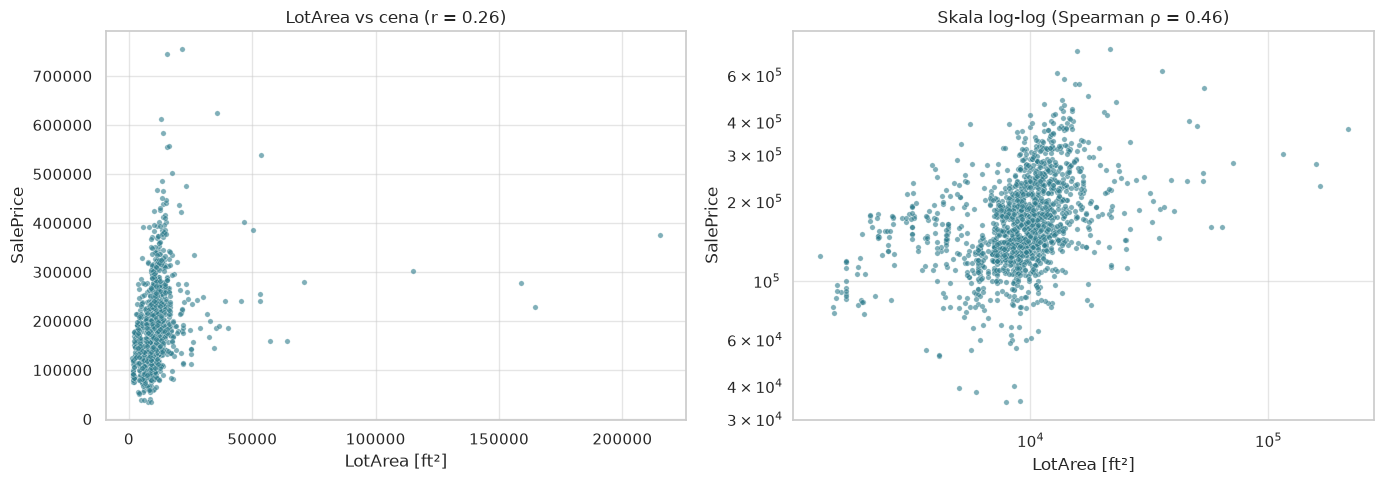

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="LotArea", y="SalePrice", s=15, alpha=.6, ax=axes[0], color="#2b7a8b")
axes[0].set_title(f"LotArea vs cena (r = {df.LotArea.corr(df.SalePrice):.2f})")
sns.scatterplot(data=df, x="LotArea", y="SalePrice", s=15, alpha=.6, ax=axes[1], color="#2b7a8b")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title(f"Skala log-log (Spearman ρ = {df.LotArea.corr(df.SalePrice, method='spearman'):.2f})")
for a in axes: a.set_xlabel("LotArea [ft²]")
plt.tight_layout()
df.nlargest(4, "LotArea")[["Id", "LotArea", "GrLivArea", "SalePrice", "Neighborhood"]]

Nie. Działka wiąże się z ceną dużo słabiej niż dom (r ≈ 0,26 wobec 0,71). Cztery największe działki mają ponad 100 000 ft² (największa 215 245 ft², ok. 2 ha), a domy na nich kosztowały od 229 do 375 tys., czyli nie wyróżniają się ceną. Te punkty mocno obniżają korelację Pearsona. W skali logarytmicznej związek widać lepiej (Spearman ≈ 0,46), ale jest umiarkowany.

### Porównanie trzech rodzajów powierzchni

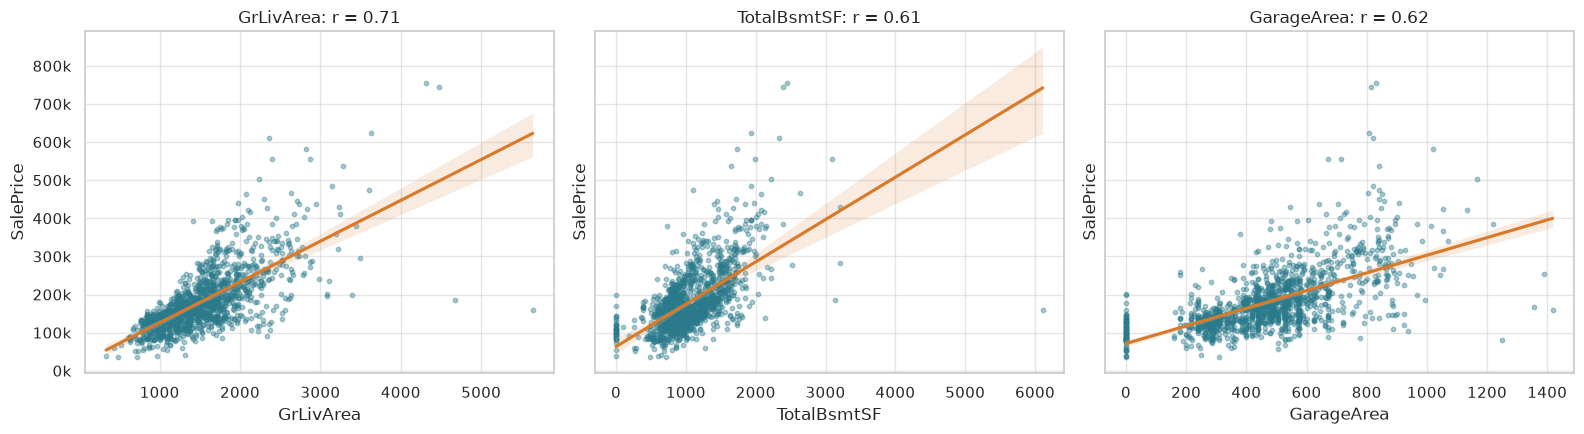

In [30]:
trzy = ["GrLivArea", "TotalBsmtSF", "GarageArea"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, c in zip(axes, trzy):
    sns.regplot(data=df, x=c, y="SalePrice", ax=ax, scatter_kws=dict(s=10, alpha=.4, color="#2b7a8b"),
                line_kws=dict(color="#d97a2b"))
    ax.set_title(f"{c}: r = {df[c].corr(df.SalePrice):.2f}")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
plt.tight_layout()

Najsilniej z ceną wiąże się `GrLivArea` (r = 0,71), potem `GarageArea` (0,62) i `TotalBsmtSF` (0,61). Na wykresach piwnicy i garażu przy zerze widać pionowy słupek punktów: to domy bez piwnicy albo bez garażu. Zero oznacza tu brak, więc w modelu warto potraktować te domy osobno. Na wykresie piwnicy znów odstaje dom 1299 (piwnica 6110 ft², niska cena).

Suma powierzchni (`TotalSF = GrLivArea + TotalBsmtSF`) jest skorelowana z ceną jeszcze silniej:

In [31]:
total_sf = df.GrLivArea + df.TotalBsmtSF
print(f"r(TotalSF, SalePrice) = {total_sf.corr(df.SalePrice):.3f}")
print(f"r(TotalSF, SalePrice) bez 2 sprzedaży Partial = {total_sf[bez.index].corr(bez.SalePrice):.3f}")

r(TotalSF, SalePrice) = 0.779
r(TotalSF, SalePrice) bez 2 sprzedaży Partial = 0.829


## Podsumowanie

1. Zmienna docelowa to `SalePrice`. Zbiór obejmuje 1460 domów z Ames sprzedanych w latach 2006-2010 i 79 cech: liczbowych, porządkowych (oceny jakości) i nominalnych (dzielnica, typ budynku). Nie ma w nim mieszkań w blokach, co ogranicza użycie modelu na rynku europejskim.
2. Większość braków danych jest pozorna. NA w `PoolQC`, `Alley`, `Fence`, `Garage*`, `Bsmt*` i `FireplaceQu` oznacza, że dom nie ma danej rzeczy. 864 z 872 braków w `MasVnrType` to napis `"None"`, który pandas zamienił na NaN. Prawdziwe braki dotyczą głównie `LotFrontage` (18%).
3. Rozkład ceny jest prawostronnie skośny (skośność 1,88): średnia 180 921 USD, mediana 163 000, Q1 = 129 975, Q3 = 214 000, IQR = 84 025, min 34 900, max 755 000. Rozkład nie jest normalny, ale `log(SalePrice)` jest prawie symetryczny.
4. 61 domów droższych niż 340 tys. to wartości odstające według reguły 1,5·IQR. Są to duże, nowe domy wysokiej jakości, a nie błędy w danych.
5. Hipoteza „większe domy są droższe” się potwierdza: dla `GrLivArea` r = 0,71, zależność jest w przybliżeniu liniowa, a rozrzut cen rośnie z wielkością domu. Działka (`LotArea`) ma dużo słabszy związek z ceną (r = 0,26).
6. Domy 524 i 1299 to bardzo duże domy sprzedane tanio w transakcjach częściowych (`Partial`). Przy budowie modelu można je wykluczyć z tego powodu.
7. Poza powierzchnią cenę silnie wyznaczają jakość (`OverallQual`, r = 0,79) i dzielnica. Kilka cech się dubluje (liczba miejsc i powierzchnia garażu, piwnica i parter), więc przy budowie modelu trzeba wybrać jedną z każdej pary.